In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv")

In [3]:
import os

print(os.getcwd())

c:\Users\Pujan Pandey\OneDrive\Projects\Network-Intrusion-Detection-Advanced-MLOps\notebooks


In [4]:
df

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
225740,61374,61,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
225741,61378,72,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
225742,61375,75,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
225743,61323,48,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [5]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 225745 entries, 0 to 225744
Data columns (total 79 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0    Destination Port             225745 non-null  int64  
 1    Flow Duration                225745 non-null  int64  
 2    Total Fwd Packets            225745 non-null  int64  
 3    Total Backward Packets       225745 non-null  int64  
 4   Total Length of Fwd Packets   225745 non-null  int64  
 5    Total Length of Bwd Packets  225745 non-null  int64  
 6    Fwd Packet Length Max        225745 non-null  int64  
 7    Fwd Packet Length Min        225745 non-null  int64  
 8    Fwd Packet Length Mean       225745 non-null  float64
 9    Fwd Packet Length Std        225745 non-null  float64
 10  Bwd Packet Length Max         225745 non-null  int64  
 11   Bwd Packet Length Min        225745 non-null  int64  
 12   Bwd Packet Length Mean       225745 non-nul

In [7]:
print(df.columns.tolist())

[' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', 'FIN Flag Count', ' SYN Flag Count', ' RST Flag Count', ' PSH Flag Count', ' ACK Flag Count', ' URG Flag 

In [8]:
df[' Label'].unique()

array(['BENIGN', 'DDoS'], dtype=object)

In [9]:
X = df.drop(columns=[" Label"])
y = df[" Label"]

In [10]:
df.columns = df.columns.str.strip()

In [11]:
print(df.columns)

Index(['Destination Port', 'Flow Duration', 'Total Fwd Packets',
       'Total Backward Packets', 'Total Length of Fwd Packets',
       'Total Length of Bwd Packets', 'Fwd Packet Length Max',
       'Fwd Packet Length Min', 'Fwd Packet Length Mean',
       'Fwd Packet Length Std', 'Bwd Packet Length Max',
       'Bwd Packet Length Min', 'Bwd Packet Length Mean',
       'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s',
       'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min',
       'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max',
       'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std',
       'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags',
       'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length',
       'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s',
       'Min Packet Length', 'Max Packet Length', 'Packet Length Mean',
       'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count',
       'SYN Flag Co

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize, StandardScaler
import matplotlib as plt
import seaborn as sns
from evidently import Report
from evidently.presets import DataDriftPreset



In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [14]:
# Find rows in X_test that also exist in X_train
train_hashes = pd.util.hash_pandas_object(
    X_train, index=False
)

test_hashes = pd.util.hash_pandas_object(
    X_test, index=False
)

overlap_mask = test_hashes.isin(train_hashes)

# Keep only non-overlapping test records
X_test_clean = X_test.loc[~overlap_mask].copy()
y_test_clean = y_test.loc[~overlap_mask].copy()

print("Original test size:", len(X_test))
print("Removed duplicates:", overlap_mask.sum())
print("Clean test size:", len(X_test_clean))
print("Clean labels size:", len(y_test_clean))

Original test size: 45149
Removed duplicates: 720
Clean test size: 44429
Clean labels size: 44429


In [15]:
comparison = pd.DataFrame({
    "Original": y.value_counts(normalize=True) * 100,
    "Training": y_train.value_counts(normalize=True) * 100,
    "Reference": y_test.value_counts(normalize=True) * 100
})

display(comparison.round(2))

,Original,Training,Reference
Label,,,
DDoS,56.71,56.71,56.71
BENIGN,43.29,43.29,43.29


In [16]:
from evidently import Report
from evidently.presets import DataDriftPreset

report = Report(metrics=[
    DataDriftPreset()
])

result = report.run(
    reference_data=X_train,
    current_data=X_test
)

result

c:\Users\Pujan Pandey\OneDrive\Projects\Network-Intrusion-Detection-Advanced-MLOps\.venv\Lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Users\Pujan Pandey\OneDrive\Projects\Network-Intrusion-Detection-Advanced-MLOps\.venv\Lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Users\Pujan Pandey\OneDrive\Projects\Network-Intrusion-Detection-Advanced-MLOps\.venv\Lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Users\Pujan Pandey\OneDrive\Projects\Network-Intrusion-Detection-Advanced-MLOps\.venv\Lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Users\Pujan Pandey\OneDrive\Projects\Network-Intrusion-Detect

In [18]:
categorical_cols = X_train.select_dtypes(include=["object"]).columns

print(categorical_cols)

Index([], dtype='object')


In [19]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)
print(y_test_encoded)
print(y_train_encoded)

[1 0 0 ... 1 1 1]
[0 1 1 ... 1 1 1]


In [20]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_train_encoded = encoder.fit_transform(X_train[categorical_cols])

X_test_encoded = encoder.transform(X_test[categorical_cols])
print(X_train_encoded)

[]


In [23]:
X_train.select_dtypes(include=["object"]).columns.tolist()
import numpy as np

In [24]:
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nData types:")
print(X_train.dtypes.value_counts())

print("\nMissing values:", X_train.isna().sum().sum())

print("\nInfinite values:",
      np.isinf(X_train.select_dtypes(include=np.number)).sum().sum())

Training shape: (180596, 78)
Testing shape: (45149, 78)

Data types:
int64      54
float64    24
Name: count, dtype: int64

Missing values: 2

Infinite values: 50


In [26]:

print("Missing values by column:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

print("\nInfinite values by column:")
inf_counts = np.isinf(X_train).sum()
print(inf_counts[inf_counts > 0])

Missing values by column:
Flow Bytes/s    2
dtype: int64

Infinite values by column:
Flow Bytes/s       24
 Flow Packets/s    26
dtype: int64


In [28]:

X_train.replace([np.inf, -np.inf], np.nan, inplace=True)
X_test.replace([np.inf, -np.inf], np.nan, inplace=True)

In [29]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

In [30]:
print("Training missing:", X_train.isna().sum().sum())

print("Testing missing:", X_test.isna().sum().sum())

print(
    "Training infinite:",
    np.isinf(X_train).sum().sum()
)

print(
    "Testing infinite:",
    np.isinf(X_test).sum().sum()
)

Training missing: 52
Testing missing: 16
Training infinite: 0
Testing infinite: 0


In [31]:
import numpy as np

Q1 = X_train_imputed.quantile(0.25)
Q3 = X_train_imputed.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (X_train_imputed < lower_bound) |
    (X_train_imputed > upper_bound)
)

outlier_counts = outlier_mask.sum()

outlier_summary = pd.DataFrame({
    "Outlier_Count": outlier_counts,
    "Outlier_Percentage": (
        outlier_counts / len(X_train_imputed)
    ) * 100
})

outlier_summary = outlier_summary.sort_values(
    "Outlier_Percentage",
    ascending=False
)

display(outlier_summary.head(20))

,Outlier_Count,Outlier_Percentage
Destination Port,71020,39.325345
Flow Bytes/s,37134,20.561917
Active Mean,35091,19.430663
Active Max,35091,19.430663
Active Min,35024,19.393564
Bwd Packets/s,32779,18.150457
Fwd Packets/s,31842,17.631620
Flow Packets/s,31327,17.346453
Flow Duration,30025,16.625507
Fwd IAT Total,29848,16.527498


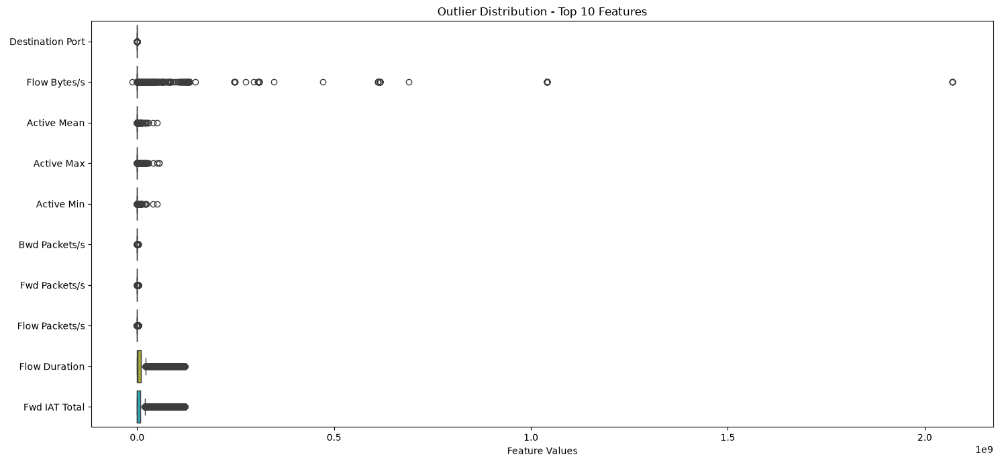

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

top_features = outlier_summary.head(10).index

plt.figure(figsize=(15, 7))

sns.boxplot(
    data=X_train_imputed[top_features],
    orient="h"
)

plt.title("Outlier Distribution - Top 10 Features")
plt.xlabel("Feature Values")
plt.tight_layout()
plt.show()

In [33]:
from sklearn.preprocessing import PowerTransformer
import pandas as pd

transformer = PowerTransformer(
    method="yeo-johnson",
    standardize=False
)

X_train_transformed = pd.DataFrame(
    transformer.fit_transform(X_train_imputed),
    columns=X_train_imputed.columns,
    index=X_train_imputed.index
)

X_test_transformed = pd.DataFrame(
    transformer.transform(X_test_imputed),
    columns=X_test_imputed.columns,
    index=X_test_imputed.index
)

In [34]:
before_skew = X_train_imputed.skew()
after_skew = X_train_transformed.skew()

comparison = pd.DataFrame({
    "Before": before_skew,
    "After": after_skew
})

display(
    comparison.reindex(
        comparison["Before"].abs().sort_values(
            ascending=False
        ).index
    ).head(20)
)

,Before,After
ECE Flag Count,92.719752,92.719752
RST Flag Count,92.719752,92.719752
Active Std,82.510938,6.072014
act_data_pkt_fwd,81.694795,-0.019983
Flow Bytes/s,73.563484,-58.917711
Total Length of Bwd Packets,69.966938,-0.070877
Subflow Bwd Bytes,69.966938,-0.070877
Subflow Bwd Packets,66.237876,-0.001391
Total Backward Packets,66.237876,-0.001391
Subflow Fwd Packets,60.231191,-0.020861


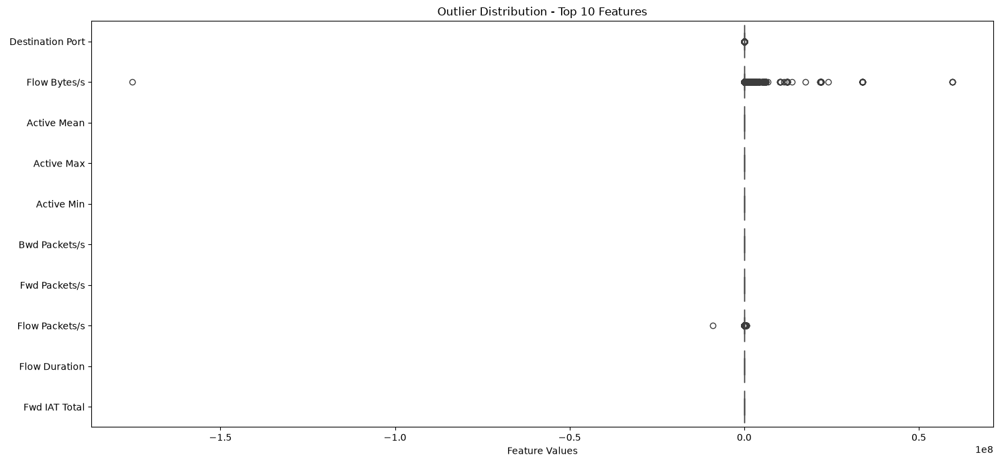

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

top_features = outlier_summary.head(10).index

plt.figure(figsize=(15, 7))

sns.boxplot(
    data=X_train_transformed[top_features],
    orient="h"
)

plt.title("Outlier Distribution - Top 10 Features")
plt.xlabel("Feature Values")
plt.tight_layout()
plt.show()

In [36]:
import numpy as np

print("Missing:", X_train_transformed.isna().sum().sum())

print("Infinite:", np.isinf(X_train_transformed).sum().sum())

Missing: 0
Infinite: 0


In [37]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_transformed),
    columns=X_train_transformed.columns,
    index=X_train_transformed.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test_transformed),
    columns=X_test_transformed.columns,
    index=X_test_transformed.index
)

In [38]:
import numpy as np

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

print("Training NaN:", X_train_scaled.isna().sum().sum())
print("Testing NaN:", X_test_scaled.isna().sum().sum())

print("Training Inf:", np.isinf(X_train_scaled).sum().sum())
print("Testing Inf:", np.isinf(X_test_scaled).sum().sum())

print("Same features:",
      X_train_scaled.columns.equals(X_test_scaled.columns))

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training shape: (180596, 78)
Testing shape: (45149, 78)
Training NaN: 0
Testing NaN: 0
Training Inf: 0
Testing Inf: 0
Same features: True
Training labels: (180596,)
Testing labels: (45149,)


In [39]:
print("Training distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training distribution:
 Label
DDoS      56.713327
BENIGN    43.286673
Name: proportion, dtype: float64

Testing distribution:
 Label
DDoS      56.71222
BENIGN    43.28778
Name: proportion, dtype: float64


In [40]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_model.fit(X_train_scaled, y_train)

y_pred = rf_model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred, pos_label="DDoS"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9999557022303927
F1 Score: 0.999960943602562

Classification Report:
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     19544
        DDoS       1.00      1.00      1.00     25605

    accuracy                           1.00     45149
   macro avg       1.00      1.00      1.00     45149
weighted avg       1.00      1.00      1.00     45149


Confusion Matrix:
[[19544     0]
 [    2 25603]]


In [41]:
import pandas as pd

# Create hashes for training and testing feature rows
train_hashes = pd.util.hash_pandas_object(
    X_train, index=False
)

test_hashes = pd.util.hash_pandas_object(
    X_test, index=False
)

# Count test records that also exist in training
overlap = test_hashes.isin(train_hashes).sum()

print("Duplicate records across datasets:", overlap)
print("Total test records:", len(X_test))
print("Overlap percentage:", overlap / len(X_test) * 100)

Duplicate records across datasets: 720
Total test records: 45149
Overlap percentage: 1.59471970586281


In [42]:
train_data = X_train.copy()
train_data["Label"] = y_train.values

test_data = X_test.copy()
test_data["Label"] = y_test.values

merged = test_data.merge(
    train_data,
    on=list(X_train.columns),
    suffixes=("_test", "_train")
)

print("Matching feature records:", len(merged))

print(
    "Matching features with different labels:",
    (merged["Label_test"] != merged["Label_train"]).sum()
)

Matching feature records: 5134
Matching features with different labels: 0
